# Weel 11: Principal Components Analysis(, Advanced Topics)

# First time here?



1.   Copy this file to your Google Drive so you can edit it: **File->Save a copy in Drive** (requires a personal Google account)
2.   Done? Consider giving your copy a better name (e.g., including your name and/or student ID) - just click on the filename in the top left and edit it.
3.   (Want to re-open your copy in future? Go: **File->Open notebook** and select the Google Drive tab)
4.   (Want to find your file on your Google Drive? Google puts Colab files in a folder called "Colab Notebooks")

# Scikit-learn implementations (PCA)

In this notebook we're going to focus on using a principal components analysis (PCA) implementation: the one provided by the [Scikit-learn](https://scikit-learn.org/stable/) package.

As well as learning how to use it, we'll also look at some methods for evaluating the results it produces.

In the extension exercises, there is a chance to work on re-implementing PCA for yourself.

# Unsupervised learning - reminder

We're doing some more unsupervised learning in this notebook. As with last time, we don't need target features for unsupervised learning. The datapoints3.csv file has 12 features but none of them is a target feature. Let's use the k-means algorithm from last time to make an elbow plot to try and work out if there are any groupings/clusters in the feature space.

## Elbow plot

In the code below we look for clusters in the range 1-10. Recall from last time that we're looking for an "elbow point" or k-value beyond which we see diminishing returns in the cost score (which is a measure of similarity between datapoints and their associated cluster centres). Run the code and consider the resulting plot:

*    Do you think there is an elbow point, and if so, what k-value would you say it occurs at? ** Yes i do think there is an elbow point in this graph and it occurs when k = 4**

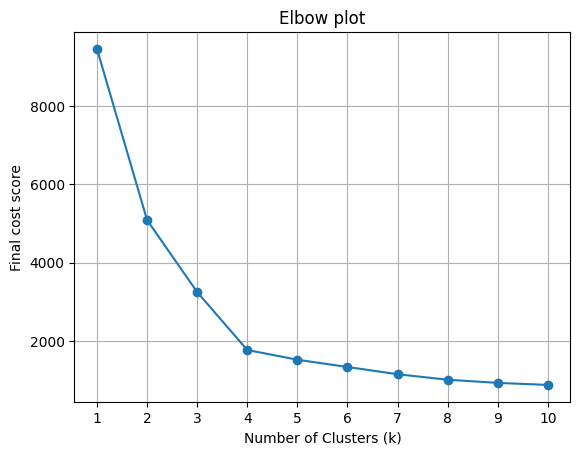

In [1]:
# Importing the packages we use
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Loading all the datapoints
datapoints = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/datapoints3.csv').to_numpy()

# Create a list to store final cost scores for different k values
costs = []

# Loop through k values from 1 to 10
for k in range(1, 11):
  # Create a k-means model object (with random cluster centre initialisations)
  kmeans = KMeans(n_clusters=k, random_state=99, init='random')

  # Run the k-means algorithm to look for cluster centres
  kmeans.fit(datapoints)

  # Store the inertia value (sum of squared distances to closest centroid)
  costs.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure()
plt.plot(range(1, 11), costs, 'o-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Final cost score')
plt.title('Elbow plot')
plt.grid(True)
plt.xticks(range(1, 11))
plt.show()

## Principal components analysis (PCA)

Now let's try applying another unsupervised learning method to our data: principal components analysis (PCA).

The code below uses Scikit-learn's [`decomposition.PCA`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) class to apply PCA to the datapoints3.csv data and plot the explained variance fraction versus the number of resulting principal components (see also this week's Moodle materials).

Essentially, the plot is telling us how much of the information in the original data we are able to retain at a given feature space dimensionality. Run the code and have a look at the resulting plot:

*    Approximately what percentage of the variance in the original datapoints3.csv data do we preserve when retaining the first 3 PCs only? ** Aprroximately 98% **



[[ 7.27889774e-01  5.45142782e-01 -4.15895475e-01  9.40962108e-04
  -1.73130657e-03 -2.27018306e-03 -1.76787554e-03  2.77858128e-04
  -2.81193841e-03  9.42490764e-04 -1.68666010e-04  2.39066884e-03]
 [-1.07482953e-01  6.89749457e-01  7.15981824e-01  2.54562583e-03
   1.35544123e-03  2.99751362e-03  2.07776715e-03  4.81441473e-03
   4.51970844e-04 -7.66359288e-04  1.97863910e-03  3.69102127e-03]
 [ 6.77070653e-01 -4.76432148e-01  5.60571830e-01 -6.39223173e-03
  -1.85350185e-03  6.16048883e-04 -3.19138526e-03  5.18759009e-03
  -2.83972186e-04  1.22997423e-02  8.25691913e-03  6.75647210e-03]
 [-2.39000696e-03 -2.81124968e-03 -2.92869165e-03  2.71489957e-01
   2.38551838e-01 -1.99518569e-01  3.60772211e-01 -6.86003454e-02
  -3.95231934e-01 -1.30755250e-01  3.65251736e-01  6.22880188e-01]
 [-4.08089702e-03 -1.14548332e-03 -7.75734036e-03  2.88767511e-01
  -2.60190797e-01  4.57723791e-01 -2.04068872e-01  6.81872447e-01
   6.91927879e-02 -2.10814976e-02  3.14800254e-01  1.68521373e-01]
 [ 7.

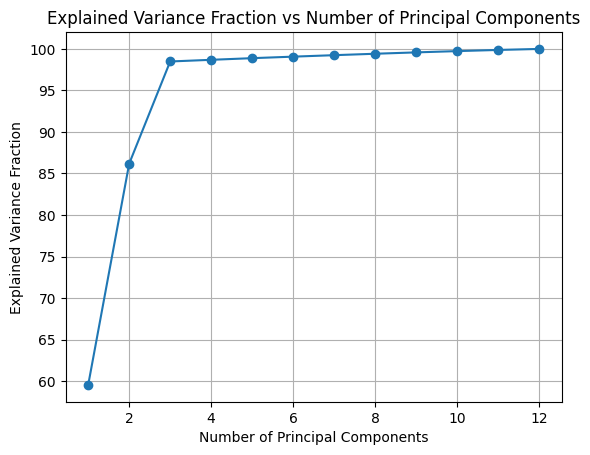

In [2]:
# Importing the packages we use
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Loading all the datapoints
datapoints = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/datapoints3.csv')

# Create a PCA model object
pca = PCA()

# Use it to process our datapoints
pca.fit(datapoints)

# See the resulting PCs (each row defines one PC / new axis)
print(pca.components_)

# Plot the cumulative explained variance against the number of PCs
plt.figure()
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_)*100, 'o-')
plt.xlabel('Number of Principal Components')
plt.ylabel('Explained Variance Fraction')
plt.title('Explained Variance Fraction vs Number of Principal Components')
plt.grid(True)
plt.show()

## Data visualisation

When we retain only the first three PCs we're still capturing the vast majority of the variation in the original data - and this is a (3D) feature space we can visualise. We can therefore use PCA to visualise the datapoint distribution (to a very close approximation).

In the code below we use the `pca` object's `transform()` method to shift our original datapoints into the new coordinate system defined by the resulting principal components (PCs), and plot their coordinates in the first three PCs.

Run the code and take some time to spin round and have a good look at the data:

*    Do you think there are clusters, and if so, how many clusters would you say there are? ** yes i do think there are clusters and i think there are 4 clusters present in the graph**



In [3]:
# Importing the packages we use
import plotly.graph_objects as go

# Transform the original datapoints to the PCA space
datapoints_pca = pca.transform(datapoints)

# Create a simple 3D scatter plot
fig = go.Figure(data=[
    go.Scatter3d(
    x=datapoints_pca[:, 0],
    y=datapoints_pca[:, 1],
    z=datapoints_pca[:, 2],
    mode='markers',
    marker=dict(size=5, opacity=0.8)
    )
])

# Set layout with axis labels
fig.update_layout(
    scene=dict(
        xaxis_title='Principal Component 1',
        yaxis_title='Principal Component 2',
        zaxis_title='Principal Component 3'
    ),
    width=800,
    height=800,
    title='datapoints3.csv - first 3 PCs'
)

# Show the interactive plot
fig.show()

# PCA in supervised learning

PCA (and other unsupervised learning methods) can also be useful to apply *within* supervised learning problems.

PCA can reduce down the number of predictive features in our supervised learning data with the following potential benefits:

*    Helping us visualise high-dimensional data
*    Helping models recover patterns in high-dimensional data
*    Helping reduce the time taken by models for training/prediction

## Data visualisation

Let's use PCA to visualise the iris.csv data for the very first time! We've processed it so many times, but it's strange to think we don't actually know what the distribution looks like (because it lies within a 4-dimensional space).

The code below takes the same data visualisation steps we took above, applying PCA to the iris.csv data, plotting the explained variance fraction versus the number of principal components, and then visualising the resulting distribution in the first three principal components.

Run the code and take some time to spin round the data and have a good look at the distribution of different irises:

*    Approximately what percentage of the variance in the original iris.csv data do we preserve when retaining the first 3 PCs only? ** 99.5 %**
*    Which two classes look like they will be most challenging for a classifier to separate (you can see the class labels by hovering over datapoints)? ** Virginica and Versicolor will be the two hardest class labels to seperate **

[[ 0.36138659 -0.08452251  0.85667061  0.3582892 ]
 [ 0.65658877  0.73016143 -0.17337266 -0.07548102]
 [-0.58202985  0.59791083  0.07623608  0.54583143]
 [ 0.31548719 -0.3197231  -0.47983899  0.75365743]]


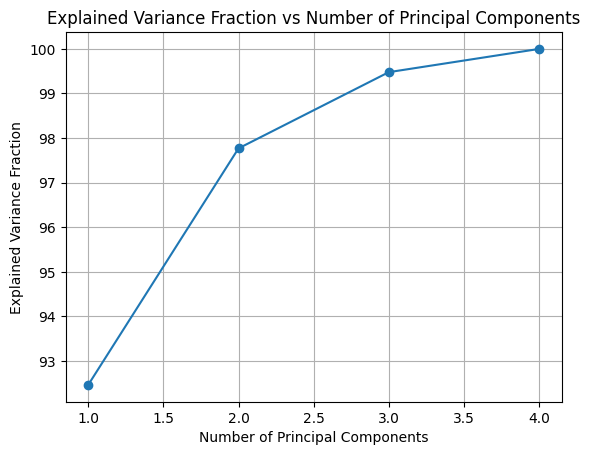

In [4]:
# Importing the packages we use
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import plotly.graph_objects as go

# Loading all the observations
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/iris.csv')

# Set the name of the target feature
target_feature = 'species'

# Split off the labels ready for some unsupervised learning
datapoints = observations.drop(columns=target_feature).to_numpy()
labels = observations[target_feature].to_numpy()

# Create a PCA model object
pca = PCA()

# Use it to process our datapoints
pca.fit(datapoints)

# See the resulting PCs (each row defines one PC / new axis)
print(pca.components_)

# Plot the cumulative explained variance against the number of PCs
plt.figure()
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_)*100, 'o-')
plt.xlabel('Number of Principal Components')
plt.ylabel('Explained Variance Fraction')
plt.title('Explained Variance Fraction vs Number of Principal Components')
plt.grid(True)
plt.show()

# Transform the original datapoints to the PCA space
datapoints_pca = pca.transform(datapoints)

# Create a simple 3D scatter plot
fig = go.Figure(data=[
    go.Scatter3d(
    x=datapoints_pca[:, 0],
    y=datapoints_pca[:, 1],
    z=datapoints_pca[:, 2],
    mode='markers',
    marker=dict(size=5, opacity=0.8, color=pd.factorize(labels)[0]),
    text=labels
    )
])

# Set layout with axis labels
fig.update_layout(
    scene=dict(
        xaxis_title='Principal Component 1',
        yaxis_title='Principal Component 2',
        zaxis_title='Principal Component 3'
    ),
    width=800,
    height=800,
    title='iris.csv - first 3 PCs'
)

# Show the interactive plot
fig.show()

## Updating the recipe

The following code cell shows how we would embed PCA within the standard supervised learning recipe, using it to train and evaluate classifiers in a new lower-dimensional space.

Have read over the code (no need to run it yet) and check you can identify the following steps:

*    We generate an explained variance fraction plot again but this time it's based on our training data only
*    We then re-fit the model, asking only to retain information about the first two PCs (see the `n_components` option)
*    We transform our training data and testing data to find its coordinates with respect to the first two PCs
*    We use the transformed training data to train a model, and the transformed testing data to evaluate the model

Run the code and answer the following questions:

*    Approximately what percentage of the variance do we preserve when retaining the first two PCs only: ** 97.8 %**
*    Using only the first two PCs, the overall accuracy of the classifier is: ** 94.6 % **

**Note**: the accuracy is still strong after reducing the feature space dimensionality in half

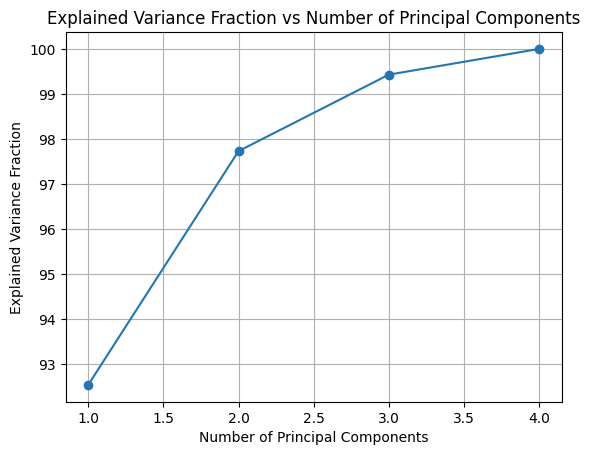

Accuracy: 0.9459459459459459 (or 94.6 %)


In [5]:
# Importing the packages we use
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

# Loading all the observations
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/iris.csv')

# Set the name of the target feature
target_feature = 'species'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.25
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create a PCA model object
pca = PCA()

# Use it to process our training examples
pca.fit(train_examples)

# Plot the cumulative explained variance against the number of PCs
plt.figure()
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_)*100, 'o-')
plt.xlabel('Number of Principal Components')
plt.ylabel('Explained Variance Fraction')
plt.title('Explained Variance Fraction vs Number of Principal Components')
plt.grid(True)
plt.show()

# Let's assume we decide to use the first 2 PCs based on the plot above...

# Create a PCA model object that only retains the first 2 PCs
pca = PCA(n_components=2)

# Use it to process our training examples
pca.fit(train_examples)

# Transform the original training examples to the new 2D space
train_examples = pca.transform(train_examples)

# Transform the original testing examples to the new 2D space
test_examples = pca.transform(test_examples)

# Create a Decision Tree model object:
model = DecisionTreeClassifier(random_state=99)

# Call the model's fitting algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

## Generalisation visualisation

The new feature space is 2D, so we can visualise the generalisation produced by the model. Try running the code below - which we normally only use with the moons.csv data:

**Tip**: Bear in mind that we're plotting the first two PCs now and they don't have an easy interpretation (like the original predictive features do)

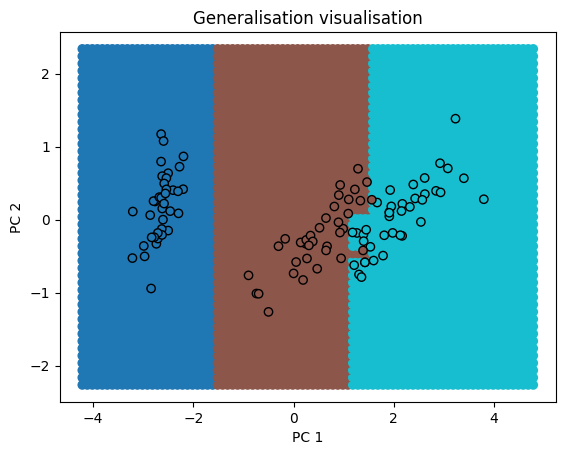

In [6]:
import matplotlib.pyplot as plt

# Prepare our own grid of testing examples to use in visualization
x_min = train_examples[:, 0].min() - 1
x_max = train_examples[:, 0].max() + 1
y_min = train_examples[:, 1].min() - 1
y_max = train_examples[:, 1].max() + 1
# adjust this to get more/less definition in the grid (takes more/less time, may need smaller plot points below)
jump = 0.1
# Get help from numpy's meshgrid() function to be fast
grid_x, grid_y = np.meshgrid(np.arange(x_min, x_max, jump), np.arange(y_min, y_max, jump))
# Turn the results back into a deep table with only 2 columns
grid_examples = np.c_[grid_x.ravel(), grid_y.ravel()]

# Make predictions for each of the examples in the grid
grid_predictions = model.predict(grid_examples)

# Visualise the final generalisation
plt.figure()

# Matplotlib wants integers for the colour codes in our scatter plot: convert our string-based labels over
unique_labels, grid_labels_int = np.unique(grid_predictions, return_inverse=True)
unique_labels, train_labels_int = np.unique(train_labels, return_inverse=True)
# Plot the generalisation
plt.scatter(grid_examples[:, 0], grid_examples[:, 1], c=grid_labels_int, cmap='tab10')
# Plot the training data
plt.scatter(train_examples[:, 0], train_examples[:, 1], c=train_labels_int, edgecolors='black', cmap='tab10')

plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.title('Generalisation visualisation')
plt.show()

## Standardisation and PCA

The correct way to apply PCA to data that also requires standardisation, is as follows:

1. Standardise the training data before applying PCA (and before thinking about explained variance fractions and the number of PCs to retain)
2. Retain the parameters of the standardisation operation for use again later on
3. Transform the standardised training data into the new PCA space and then train your predictive model
4. Apply the same standardisation parameters learned from the training data (step 2) to the testing data
5. Transform the standardised testing data into the new PCA space and use it to evaluate your predictive model

By following these steps, halve the dimensionality of the feature space for the biopsies.csv data (which needs standardisation) and see what performance you get with a k-NN classifier using k=5, a 75/25 holdout split and `random_state=99`:

*    Using only the first 15 PCs, the overall accuracy of the classifier is: ** 97.2 %**

**Tip**: the case for standardising alongside PCA isn't always clear-cut - see the Moodle materials for further discussion

In [13]:
# Add your code on the lines below
# Imports
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

# Load data
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

target_feature = 'diagnosis'

# Split into X and y
X = observations.drop(columns=target_feature).to_numpy()
y = observations[target_feature].to_numpy()

# Train/test split (75/25)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=99
)


# Standardisation

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#  PCA (halve dimensions)

n_features = X_train.shape[1]
pca = PCA(n_components= 15)

X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)


#  k-NN model (k=5)

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)


#Evaluate

predictions = model.predict(X_test)

accuracy = np.mean(predictions == y_test)

print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")





Accuracy: 0.972027972027972 (or 97.2 %)


# Extension tasks (optional)

(Extension tasks are optional. They don't map to the assessment on this module and there is no harm in skipping them. However, for people who are interested in the subject/planning to do further study, the extension tasks can help you deepen your machine learning knowledge and meet the module learning objectives more fully.)

## Manual transformations

In the code below, we repeat the same supervised learning + PCA approach we took in the previous section with iris.csv, but this time we do the transformations manually, using matrix multiplications (see also the Moodle materials). Have a look over the code and then run it to make sure you see the same accuracy:

*    Using only the first two PCs, the overall accuracy of the classifier is: **Type your answer here**

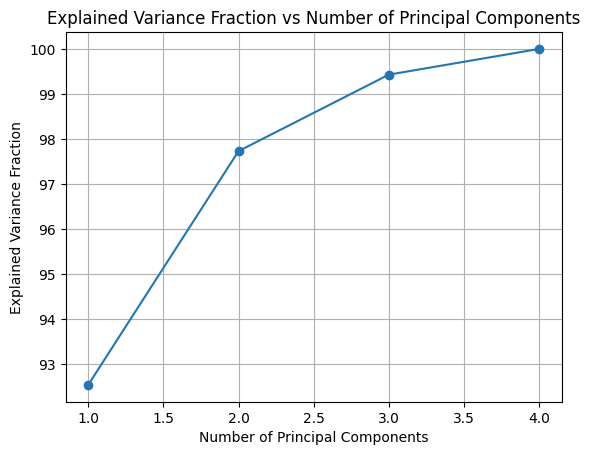

Accuracy: 0.9459459459459459 (or 94.6 %)


In [ ]:
# Importing the packages we use
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

# Loading all the observations
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/iris.csv')

# Set the name of the target feature
target_feature = 'species'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.25
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create a PCA model object
pca = PCA()

# Use it to process our training examples
pca.fit(train_examples)

# Plot the cumulative explained variance against the number of PCs
plt.figure()
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_)*100, 'o-')
plt.xlabel('Number of Principal Components')
plt.ylabel('Explained Variance Fraction')
plt.title('Explained Variance Fraction vs Number of Principal Components')
plt.grid(True)
plt.show()

# Let's assume we decide to use the first 2 PCs based on the plot above...

# Calculate the means of all the training feature values
means = np.mean(train_examples[:, :], axis=0)

# Shift the training data and the testing data using the same transformation
train_examples_centred = train_examples - means

# Shift the testing data and the testing data using the same transformation
test_examples_centred = test_examples - means

# Note scikit-learn's .components_ attribute actually holds one PC per row... Hence us transposing it to look as we expect, below

# Transform the original training examples to the new space (matrix multiply between centred data and principle components)
train_examples = train_examples_centred @ pca.components_.T

# And "delete" everything after the 2nd column
train_examples = train_examples[:, :2]

# Or, equivalently, we could have multiplied with only the first two PCs... Let's use that approach to transform the testing examples
test_examples = test_examples_centred @ pca.components_[:2, :].T

# Create a Decision Tree model object:
model = DecisionTreeClassifier(random_state=99)

# Call the model's fitting algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with the corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

## You try

By using NumPy's `linalg.svd` function to perform the Singular Value Decomposition (SVD) factorisation mentioned in the Moodle materials, would you like to re-implement a `my_pca` class for principal components analysis.

Your class should:

*    Centre any data it is handed, and store the parameters of that operation
*    Perform SVD to find the PCs (from the third matrix) and the explained variance fractions (from the diagonal elements of the second matrix), and store them both
*    Offer a `.transform()` method allowing the caller to transform data into the recovered space using the stored parameters (and, once that's working, an extra `n_components` option to control the number of PCs considered)

**Tip** looking at how the manual transformations were performed in the previous section should be helpful

You may not get *identical* PCs to the ones generated by Scikit-learn (e.g., they may point in the opposite directions), but add code below check you still get good supervised learning performance with the iris.csv and/or biopsies.csv data, below:

In [ ]:
# Add your code on the lines below



